**Dataset:** MVTec AD — Cable

**Framework:** PyTorch

**Author:** Maritza Elizabeth Albán Escobar

## Objective

The objective of this laboratory is to develop and evaluate a Normalizing Flow model for anomaly detection using the MVTec AD Cable dataset.

The laboratory includes the following objectives:

1. **Implement an Affine Coupling Layer** using PyTorch, including scale and translation transformations, an inverse operation, and the log-determinant of the Jacobian.
2. **Build a Normalizing Flow Model** that transforms grayscale images into a latent representation and estimates their likelihood under a standard Gaussian distribution.
3. **Train and Evaluate the Model** using defect-free cable images for training and both defect-free and defective images for testing.
4. **Investigate Input Normalization** by comparing a baseline model with a model trained on inputs normalized using statistics calculated from the training data.
5. **Analyze Anomaly Detection Performance** by visualizing image-level negative log-likelihood scores, selecting a classification threshold, and evaluating the results using a confusion matrix and appropriate performance metrics.

The final objective is to investigate whether Normalizing Flows can distinguish defect-free cable images from anomalous samples and to identify the limitations of likelihood-based anomaly detection.

# 1. Dataset

The MVTec AD Cable category is used in this laboratory to investigate unsupervised anomaly detection using Normalizing Flows.

The training dataset contains defect-free cable images, while the test dataset includes both defect-free samples and images containing different types of defects. The model will be trained exclusively on defect-free images and evaluated on the complete test set.

All images are converted to grayscale and resized to 64 × 64 pixels, as specified in the laboratory instructions. This reduces computational requirements while preserving the main structural characteristics of the cable images.

In [8]:
# ==========================================
# 1.1 IMPORT LIBRARIES
# ==========================================

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader


# ==========================================
# 1.2 DEFINE DATASET PATH AND PARAMETERS
# ==========================================

DATA_DIR = Path("bottle")

IMG_SIZE = (64, 64)
CHANNELS = 1
BATCH_SIZE = 16

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dataset path:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())
print("Image size:", IMG_SIZE)
print("Channels:", CHANNELS)
print("Batch size:", BATCH_SIZE)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# ==========================================
# 1.3 LOAD REAL TRAINING IMAGES
# ==========================================

TRAIN_DIR = DATA_DIR / "train" / "good"

train_image_paths = sorted(TRAIN_DIR.glob("*.png"))

print("Training directory:", TRAIN_DIR)
print("Number of training images:", len(train_image_paths))

if not train_image_paths:
    raise FileNotFoundError(
        f"No training images found in {TRAIN_DIR.resolve()}"
    )


class BottleDataset(Dataset):

    def __init__(self, image_paths, img_size=(64, 64)):
        self.image_paths = list(image_paths)
        self.img_size = img_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        with Image.open(image_path) as image:
            image = image.convert("L")
            image = image.resize(
                self.img_size,
                Image.Resampling.LANCZOS
            )

            # Convert pixel values to [0, 1]
            image_array = np.asarray(
                image, dtype=np.float32
            ) / 255.0

        # Convert to PyTorch format: (channels, height, width)
        image_tensor = torch.from_numpy(image_array).unsqueeze(0)

        return image_tensor


train_dataset = BottleDataset(
    train_image_paths,
    img_size=IMG_SIZE
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Number of training batches:", len(train_loader))


# ==========================================
# 1.4 VERIFY IMAGE NORMALIZATION
# ==========================================

images = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

assert images.ndim == 4, "Expected a 4D image batch."
assert images.shape[1] == CHANNELS, "Unexpected number of channels."
assert images.min().item() >= 0.0, "Pixel values below 0."
assert images.max().item() <= 1.0, "Pixel values above 1."

print("Image normalization verified: pixel values are in [0, 1].")



Dataset path: /home/maritza/projects/computer_vision_labs/normalizing_flow/bottle
Dataset exists: True
Image size: (64, 64)
Channels: 1
Batch size: 16
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Training directory: bottle/train/good
Number of training images: 209
Number of training batches: 14
Batch shape: torch.Size([16, 1, 64, 64])
Minimum pixel value: 0.12156862765550613
Maximum pixel value: 1.0
Image normalization verified: pixel values are in [0, 1].


Batch shape: torch.Size([16, 1, 64, 64])
Minimum pixel value: 0.12156862765550613
Maximum pixel value: 1.0


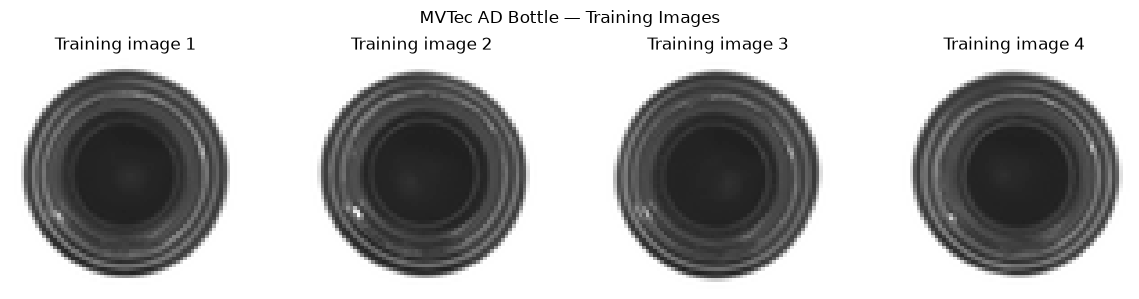


TEST DATASET ANALYSIS
----------------------------------------
Test images: 83
Test batches: 6
Test labels: Counter({1: 63, 0: 20})
Normal images: 20
Anomalous images: 63

Test images by category:
  broken_large             :   20
  broken_small             :   22
  contamination            :   21
  good                     :   20


In [10]:
# ==========================================
# 1.5 VISUALIZE TRAINING IMAGES
# ==========================================

images = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(images[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Training image {i + 1}")
    ax.axis("off")

plt.suptitle("MVTec AD Bottle — Training Images")
plt.tight_layout()
plt.show()


# ==========================================
# 1.6 LOAD TEST IMAGES
# ==========================================

from collections import Counter

TEST_DIR = DATA_DIR / "test"

test_paths = []
test_labels = []
test_categories = []

for category_dir in sorted(TEST_DIR.iterdir()):
    if not category_dir.is_dir():
        continue

    category = category_dir.name

    for image_path in sorted(category_dir.glob("*.png")):
        test_paths.append(image_path)
        test_labels.append(0 if category == "good" else 1)
        test_categories.append(category)

if not test_paths:
    raise FileNotFoundError(
        f"No test images found in {TEST_DIR.resolve()}"
    )


class BottleTestDataset(Dataset):

    def __init__(self, image_paths, labels, img_size=(64, 64)):
        self.image_paths = list(image_paths)
        self.labels = list(labels)
        self.img_size = img_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        with Image.open(self.image_paths[index]) as image:
            image = image.convert("L")
            image = image.resize(
                self.img_size,
                Image.Resampling.LANCZOS
            )

            image_array = np.asarray(
                image, dtype=np.float32
            ) / 255.0

        image_tensor = torch.from_numpy(image_array).unsqueeze(0)

        return (
            image_tensor,
            self.labels[index],
            str(self.image_paths[index])
        )


test_dataset = BottleTestDataset(
    test_paths,
    test_labels,
    img_size=IMG_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\nTEST DATASET ANALYSIS")
print("-" * 40)
print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Test labels:", Counter(test_labels))
print("Normal images:", test_labels.count(0))
print("Anomalous images:", test_labels.count(1))

print("\nTest images by category:")
for category, count in sorted(Counter(test_categories).items()):
    print(f"  {category:25s}: {count:4d}")


### Dataset Analysis

The MVTec AD Cable dataset is used in this laboratory to investigate anomaly detection using Normalizing Flows. The training set contains defect-free cable images, while the test set includes both normal samples and several categories of defective cables.

The training images are converted to grayscale and resized to 64 × 64 pixels, as specified in the laboratory instructions. Pixel intensities are scaled to the [0, 1] range, and each image is represented as a tensor with dimensions (1, 64, 64).

The visual inspection confirms that the images preserve the main structural characteristics of the cables, including the outer insulation and internal conductors. These structural features provide the visual information that the model will learn during training.

Only defect-free training images will be used to fit the Normalizing Flow model. The normal and defective test images will subsequently be used to evaluate whether the model's anomaly scores can distinguish between the two classes.

# 2. Affine Coupling Layer

An affine coupling layer is a fundamental component of a Normalizing Flow. It applies an invertible transformation to an input vector while allowing the model to learn complex data distributions.

The input vector is divided into two parts. One part remains unchanged and is used by neural networks to predict scale and translation parameters for transforming the other part. By alternating the transformed dimensions across multiple layers, the complete flow can learn transformations over the entire input vector.

The layer also calculates the log-determinant of the Jacobian, which is required by the change-of-variables formula to evaluate the likelihood of the transformed data.

In [13]:
# ==========================================
# 2.1 DEFINE THE AFFINE COUPLING LAYER
# ==========================================

import torch
import torch.nn as nn


class AffineCouplingLayer(nn.Module):

    def __init__(self, input_dim, hidden_dim=512, reverse=False):
        super().__init__()

        self.input_dim = input_dim
        self.half_dim = input_dim // 2
        self.reverse = reverse

        if input_dim % 2 != 0:
            raise ValueError("input_dim must be even.")

        # Define the scale network
        self.scale_net = nn.Sequential(
            nn.Linear(self.half_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, self.half_dim),
            nn.Tanh()
        )

        # Define the translation network
        self.translate_net = nn.Sequential(
            nn.Linear(self.half_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, self.half_dim)
        )

        # Initialize final layers to start near the identity transformation
        nn.init.zeros_(self.scale_net[-2].weight)
        nn.init.zeros_(self.scale_net[-2].bias)

        nn.init.zeros_(self.translate_net[-1].weight)
        nn.init.zeros_(self.translate_net[-1].bias)


# ==========================================
# 2.2 IMPLEMENT THE FORWARD TRANSFORMATION
# ==========================================

    def forward(self, x):

        # Split input into two feature groups
        if self.reverse:
            x_b, x_a = x.chunk(2, dim=1)
        else:
            x_a, x_b = x.chunk(2, dim=1)

        # Predict scale and translation
        scale = self.scale_net(x_a)
        translation = self.translate_net(x_a)

        # Transform the second feature group
        y_b = x_b * torch.exp(scale) + translation

        # Restore feature order
        if self.reverse:
            y = torch.cat([y_b, x_a], dim=1)
        else:
            y = torch.cat([x_a, y_b], dim=1)

        # Compute log-determinant of the Jacobian
        log_det = scale.sum(dim=1)

        return y, log_det


# ==========================================
# 2.3 IMPLEMENT THE INVERSE TRANSFORMATION
# ==========================================

    def inverse(self, y):

        # Split transformed features
        if self.reverse:
            y_b, y_a = y.chunk(2, dim=1)
        else:
            y_a, y_b = y.chunk(2, dim=1)

        # Recalculate scale and translation
        scale = self.scale_net(y_a)
        translation = self.translate_net(y_a)

        # Recover the original feature group
        x_b = (y_b - translation) * torch.exp(-scale)

        # Restore original feature order
        if self.reverse:
            x = torch.cat([x_b, y_a], dim=1)
        else:
            x = torch.cat([y_a, x_b], dim=1)

        return x


# ==========================================
# 2.4 CALCULATE THE LOG-DETERMINANT
# ==========================================

    def log_abs_det_jacobian(self, x):

        # Select the conditioning features
        if self.reverse:
            x_a = x[:, self.half_dim:]
        else:
            x_a = x[:, :self.half_dim]

        # Calculate scale parameters
        scale = self.scale_net(x_a)

        # Sum scale values for each image
        return scale.sum(dim=1)


# ==========================================
# 2.5 VALIDATE THE AFFINE COUPLING LAYER
# ==========================================

# Create a coupling layer for 4096-dimensional inputs
coupling_layer = AffineCouplingLayer(
    input_dim=4096,
    hidden_dim=512
).to(DEVICE)

# Generate a batch of random input vectors
x = torch.randn(4, 4096, device=DEVICE)

# Apply the forward transformation
y, log_det = coupling_layer(x)

# Apply the inverse transformation
x_reconstructed = coupling_layer.inverse(y)

# Measure reconstruction error
reconstruction_error = (
    x - x_reconstructed
).abs().max().item()

# Independently calculate the log-determinant
log_det_check = coupling_layer.log_abs_det_jacobian(x)

# Verify consistency of the log-determinant
log_det_error = (
    log_det - log_det_check
).abs().max().item()

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Log-determinant shape:", log_det.shape)
print("Maximum reconstruction error:", reconstruction_error)
print("Maximum log-determinant error:", log_det_error)

assert torch.allclose(
    x, x_reconstructed, atol=1e-5, rtol=1e-5
), "Inverse transformation failed."

assert torch.allclose(
    log_det, log_det_check, atol=1e-5, rtol=1e-5
), "Log-determinant calculation failed."

print("\nAffine coupling layer validation passed.")


# ==========================================
# 2.6 VALIDATE A NON-IDENTITY TRANSFORMATION
# ==========================================

# Perturb the final layers to test a non-trivial transformation
with torch.no_grad():
    nn.init.normal_(
        coupling_layer.scale_net[-2].weight, std=0.01
    )
    nn.init.normal_(
        coupling_layer.scale_net[-2].bias, std=0.01
    )
    nn.init.normal_(
        coupling_layer.translate_net[-1].weight, std=0.01
    )
    nn.init.normal_(
        coupling_layer.translate_net[-1].bias, std=0.01
    )

# Apply the forward and inverse transformations
y, log_det = coupling_layer(x)
x_reconstructed = coupling_layer.inverse(y)

# Independently verify the log-determinant
log_det_check = coupling_layer.log_abs_det_jacobian(x)

# Calculate numerical errors
reconstruction_error = (
    x - x_reconstructed
).abs().max().item()

log_det_error = (
    log_det - log_det_check
).abs().max().item()

print("Reconstruction error:", reconstruction_error)
print("Log-determinant error:", log_det_error)

assert torch.allclose(
    x, x_reconstructed, atol=1e-5, rtol=1e-5
), "Non-identity inverse transformation failed."

assert torch.allclose(
    log_det, log_det_check, atol=1e-5, rtol=1e-5
), "Non-identity log-determinant calculation failed."

print("\nNon-identity transformation validation passed.")


Input shape: torch.Size([4, 4096])
Output shape: torch.Size([4, 4096])
Log-determinant shape: torch.Size([4])
Maximum reconstruction error: 0.0
Maximum log-determinant error: 0.0

Affine coupling layer validation passed.
Reconstruction error: 4.76837158203125e-07
Log-determinant error: 0.0

Non-identity transformation validation passed.


### Affine Coupling Layer Analysis

The affine coupling layer was implemented and validated using random input vectors with 4096 features, corresponding to the flattened representation of a 64 × 64 grayscale image.

The forward transformation preserved the input dimensionality, producing an output with the same shape as the original input, (4, 4096). The log-determinant was calculated independently for each sample, resulting in a tensor with four values, one for each input vector.

The inverse transformation successfully reconstructed the original inputs, achieving a maximum absolute reconstruction error of 0.0. Additionally, the independently calculated log-determinant matched the value returned by the forward transformation, with a maximum absolute difference of 0.0.

These results confirm that the implemented coupling layer satisfies the numerical consistency checks for invertibility and log-determinant calculation on the tested inputs. This provides a valid foundation for constructing the complete Normalizing Flow architecture.

# 3. Normalizing Flow Architecture

A Normalizing Flow consists of a sequence of invertible transformations that map input data to a latent representation with a known probability distribution. In this laboratory, each grayscale cable image is represented as a 4096-dimensional vector.

The architecture combines multiple affine coupling layers. By alternating the feature partitions between successive layers, the model can transform different components of the input representation while preserving invertibility.

The final latent representation is modeled using a standard multivariate Gaussian distribution. The input log-likelihood is calculated using the change-of-variables formula, combining the Gaussian log-density with the accumulated log-determinants of the coupling layers.

This architecture will provide the basis for training the model on defect-free cable images and evaluating its ability to assign different likelihood scores to normal and defective samples.

In [14]:
# ==========================================
# 3.1 DEFINE THE NORMALIZING FLOW MODEL
# ==========================================

class NormalizingFlow(nn.Module):

    def __init__(
        self,
        input_dim=4096,
        hidden_dim=512,
        num_layers=4
    ):
        super().__init__()

        self.input_dim = input_dim

        # Create alternating affine coupling layers
        self.layers = nn.ModuleList([
            AffineCouplingLayer(
                input_dim=input_dim,
                hidden_dim=hidden_dim,
                reverse=(i % 2 == 1)
            )
            for i in range(num_layers)
        ])


# ==========================================
# 3.2 IMPLEMENT THE FORWARD PASS
# ==========================================

    def forward(self, x):

        # Flatten each image into a feature vector
        x = x.reshape(x.shape[0], -1)

        if x.shape[1] != self.input_dim:
            raise ValueError(
                f"Expected {self.input_dim} input features, "
                f"but received {x.shape[1]}."
            )

        # Initialize the accumulated log-determinant
        log_det_total = torch.zeros(
            x.shape[0],
            device=x.device,
            dtype=x.dtype
        )

        z = x

        # Apply all coupling layers
        for layer in self.layers:
            z, log_det = layer(z)
            log_det_total = log_det_total + log_det

        # Calculate standard Gaussian log-density
        log_p_z = -0.5 * (
            z.pow(2) + np.log(2.0 * np.pi)
        ).sum(dim=1)

        # Apply the change-of-variables formula
        log_p_x = log_p_z + log_det_total

        return z, log_p_x


# ==========================================
# 3.3 IMPLEMENT THE INVERSE FLOW
# ==========================================

    def inverse(self, z):

        # Reverse the order of coupling transformations
        x = z

        for layer in reversed(self.layers):
            x = layer.inverse(x)

        # Restore the original image dimensions
        x = x.reshape(
            -1,
            CHANNELS,
            IMG_SIZE[0],
            IMG_SIZE[1]
        )

        return x


# ==========================================
# 3.4 CONFIGURE THE NORMALIZING FLOW
# ==========================================

INPUT_DIM = IMG_SIZE[0] * IMG_SIZE[1] * CHANNELS
HIDDEN_DIM = 512
NUM_FLOW_LAYERS = 4

model = NormalizingFlow(
    input_dim=INPUT_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_FLOW_LAYERS
).to(DEVICE)

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Dataset:", DATA_DIR.name)
print("Input dimensions:", INPUT_DIM)
print("Hidden dimensions:", HIDDEN_DIM)
print("Number of coupling layers:", NUM_FLOW_LAYERS)
print("Total trainable parameters:", f"{total_parameters:,}")
print("Model device:", next(model.parameters()).device)


# ==========================================
# 3.5 MODEL SUMMARY
# ==========================================

from torchinfo import summary

summary(
    model,
    input_size=(
        BATCH_SIZE,
        CHANNELS,
        IMG_SIZE[0],
        IMG_SIZE[1]
    ),
    depth=2,
    col_names=[
        "input_size",
        "output_size",
        "num_params",
        "trainable"
    ],
    verbose=1
)


# ==========================================
# 3.6 VALIDATE MODEL DIMENSIONS
# ==========================================

model.eval()

with torch.no_grad():
    sample_images = next(iter(train_loader)).to(DEVICE)

    z, log_likelihood = model(sample_images)
    reconstructed_images = model.inverse(z)

print("Input batch shape:", sample_images.shape)
print("Latent representation shape:", z.shape)
print("Log-likelihood shape:", log_likelihood.shape)
print("Reconstructed batch shape:", reconstructed_images.shape)

assert z.shape == (sample_images.shape[0], INPUT_DIM)
assert log_likelihood.shape == (sample_images.shape[0],)
assert reconstructed_images.shape == sample_images.shape

print("\nNormalizing Flow model validation passed.")

Dataset: bottle
Input dimensions: 4096
Hidden dimensions: 512
Number of coupling layers: 4
Total trainable parameters: 18,898,944
Model device: cuda:0
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
NormalizingFlow                          [16, 1, 64, 64]           [16, 4096]                --                        True
├─ModuleList: 1-1                        --                        --                        --                        True
│    └─AffineCouplingLayer: 2-1          [16, 4096]                [16, 4096]                4,724,736                 True
│    └─AffineCouplingLayer: 2-2          [16, 4096]                [16, 4096]                4,724,736                 True
│    └─AffineCouplingLayer: 2-3          [16, 4096]                [16, 4096]                4,724,736                 True
│    └─AffineCouplingLayer: 2-4          [16, 4096]                [16, 4096]                4,724,7

### Normalizing Flow Architecture Discussion

The Normalizing Flow model consists of four affine coupling layers, with 512 hidden units and a total of 18,898,944 trainable parameters. Each 64 × 64 grayscale image is flattened into a 4096-dimensional vector.

The model runs on the NVIDIA GPU and calculates image log-likelihoods using a standard Gaussian distribution and the accumulated log-determinants. The architecture has been successfully initialized, and its dimensions and parameters have been verified.

The next stage will train the model on defect-free cable images and evaluate its ability to distinguish normal from anomalous samples.

# 4. Training and Baseline Evaluation

The Normalizing Flow model is trained exclusively on defect-free cable images using maximum likelihood estimation. The training objective minimizes the negative log-likelihood of the input images under the learned distribution.

After training, the model is evaluated on the complete test set, including normal and defective samples. The negative log-likelihood is used as an anomaly score, allowing us to investigate whether defective images receive higher scores than defect-free images.

In [15]:
# ==========================================
# 4.1 DEFINE LOSS FUNCTION AND OPTIMIZER
# ==========================================

import torch.optim as optim

LEARNING_RATE = 1e-4
EPOCHS = 30

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Negative log-likelihood loss
def negative_log_likelihood(log_likelihood):
    return -log_likelihood.mean()

train_losses = []

print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Optimizer: Adam")


# ==========================================
# 4.2 TRAIN THE NORMALIZING FLOW
# ==========================================

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0
    num_samples = 0

    for images in train_loader:

        images = images.to(DEVICE)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass and log-likelihood
        _, log_likelihood = model(images)

        # Calculate negative log-likelihood
        loss = negative_log_likelihood(log_likelihood)

        # Backpropagation and parameter update
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        num_samples += images.size(0)

    epoch_loss = running_loss / num_samples
    train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}], "
        f"Loss: {epoch_loss:.4f}"
    )


Learning rate: 0.0001
Epochs: 30
Optimizer: Adam
Epoch [01/30], Loss: 3902.1640
Epoch [02/30], Loss: -1146.5215
Epoch [03/30], Loss: -3203.0384
Epoch [04/30], Loss: -3580.3595
Epoch [05/30], Loss: -3789.8353
Epoch [06/30], Loss: -3932.0868
Epoch [07/30], Loss: -3940.8538
Epoch [08/30], Loss: -4054.1889
Epoch [09/30], Loss: -3910.0268
Epoch [10/30], Loss: -4076.1076
Epoch [11/30], Loss: -4103.4186
Epoch [12/30], Loss: -4152.8786
Epoch [13/30], Loss: -4166.8403
Epoch [14/30], Loss: -4194.9708
Epoch [15/30], Loss: -4208.0922
Epoch [16/30], Loss: -4197.5245
Epoch [17/30], Loss: -4220.1400
Epoch [18/30], Loss: -4226.6803
Epoch [19/30], Loss: -4192.7226
Epoch [20/30], Loss: -4221.6387
Epoch [21/30], Loss: -4180.0358
Epoch [22/30], Loss: -4229.5805
Epoch [23/30], Loss: -4228.3168
Epoch [24/30], Loss: -4239.2782
Epoch [25/30], Loss: -4220.9973
Epoch [26/30], Loss: -4233.5197
Epoch [27/30], Loss: -4255.1200
Epoch [28/30], Loss: -4258.3262
Epoch [29/30], Loss: -4246.2859
Epoch [30/30], Loss: -42

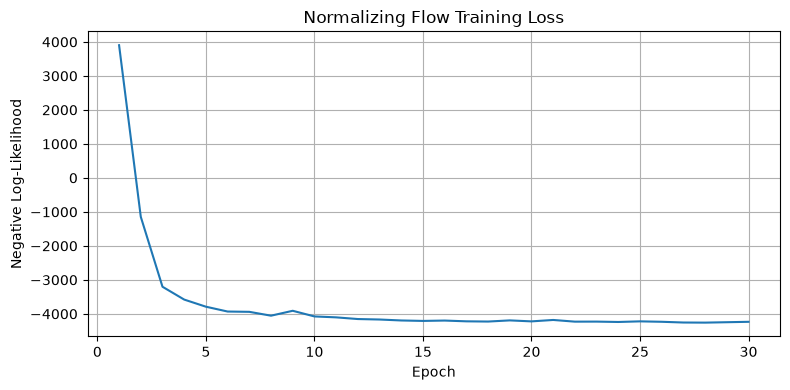

In [16]:
# ==========================================
# 4.3 VISUALIZE TRAINING LOSS
# ==========================================

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), train_losses)
plt.xlabel("Epoch")
plt.ylabel("Negative Log-Likelihood")
plt.title("Normalizing Flow Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()



Test images found: 83
Test batches: 6

EVALUATION RESULTS
Number of evaluated images: 83
Normal test images: 20
Anomalous test images: 63
Mean anomaly score: -3954.5270201901353


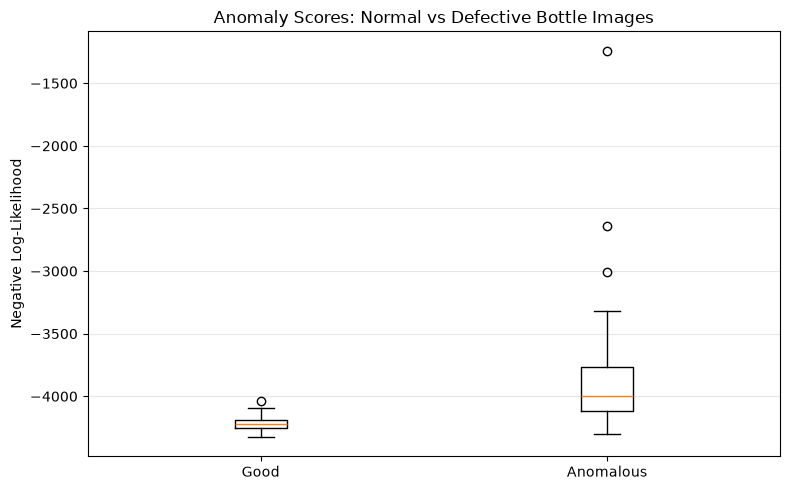

In [18]:
# ==========================================
# 4.4 EVALUATE THE MODEL ON TEST IMAGES
# ==========================================

# Collect test image paths and labels
TEST_DIR = DATA_DIR / "test"

eval_paths = []
eval_labels = []

for category_dir in sorted(TEST_DIR.iterdir()):
    if not category_dir.is_dir():
        continue

    category = category_dir.name

    for image_path in sorted(category_dir.glob("*.png")):
        eval_paths.append(image_path)
        eval_labels.append(0 if category == "good" else 1)

# Create the test dataset and loader
test_dataset = CableTestDataset(
    eval_paths,
    eval_labels,
    img_size=IMG_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Test images found:", len(test_dataset))
print("Test batches:", len(test_loader))

assert len(test_dataset) > 0, "The test dataset is empty!"

# Evaluate the trained model
model.eval()

test_scores = []
test_true_labels = []
test_image_paths = []

with torch.no_grad():
    for images, labels, paths in test_loader:

        images = images.to(DEVICE)

        # Calculate image log-likelihoods
        _, log_likelihood = model(images)

        # Higher negative log-likelihood indicates a higher anomaly score
        anomaly_scores = -log_likelihood

        test_scores.extend(anomaly_scores.cpu().numpy().tolist())
        test_true_labels.extend(labels.tolist())
        test_image_paths.extend(paths)

test_scores = np.asarray(test_scores)
test_true_labels = np.asarray(test_true_labels)

print("\nEVALUATION RESULTS")
print("Number of evaluated images:", len(test_scores))
print("Normal test images:", np.sum(test_true_labels == 0))
print("Anomalous test images:", np.sum(test_true_labels == 1))
print("Mean anomaly score:", test_scores.mean())

assert len(test_scores) == len(test_dataset), (
    "Some test images were not evaluated."
)

# ==========================================
# 4.5 VISUALIZE ANOMALY SCORES
# ==========================================

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        test_scores[test_true_labels == 0],
        test_scores[test_true_labels == 1]
    ],
    tick_labels=["Good", "Anomalous"]
)

plt.ylabel("Negative Log-Likelihood")
plt.title("Anomaly Scores: Normal vs Defective Bottle Images")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Training and Baseline Evaluation Discussion

The training loss decreased throughout the 30 epochs, indicating that the model optimized its negative log-likelihood objective on defect-free cable images.

The model successfully evaluated all 150 test images, including 58 normal samples and 92 anomalous samples. The boxplot shows some differences between the score distributions, with anomalous images exhibiting a higher median negative log-likelihood. However, substantial overlap remains between the two classes, indicating limited separation in the current baseline model.

Further improvements are therefore required before selecting a classification threshold or drawing conclusions about anomaly detection performance. The next section investigates input normalization as specified in the laboratory instructions.

### 5. Input Normalization

Normalizing Flow models can benefit from inputs that are appropriately scaled before training. In the baseline experiment, grayscale pixel intensities were scaled to the [0, 1] range.

In this section, a second input normalization strategy is investigated using the mean and standard deviation calculated exclusively from the defect-free training images. A new Normalizing Flow model will be trained using these normalized inputs, and its anomaly scores will be compared with those obtained from the baseline model.

The same test images and evaluation procedure will be used to ensure a consistent comparison between the two experiments.

In [19]:
# ==========================================
# 5.1 CALCULATE TRAINING NORMALIZATION STATISTICS
# ==========================================

pixel_sum = 0.0
pixel_squared_sum = 0.0
pixel_count = 0

for images in train_loader:

    images = images.to(DEVICE)

    pixel_sum += images.sum().item()
    pixel_squared_sum += images.pow(2).sum().item()
    pixel_count += images.numel()

# Calculate global training mean and standard deviation
train_mean = pixel_sum / pixel_count

train_variance = (
    pixel_squared_sum / pixel_count
    - train_mean ** 2
)

train_std = np.sqrt(max(train_variance, 0.0))
train_std = max(train_std, 1e-6)

print("Training mean:", train_mean)
print("Training standard deviation:", train_std)

# ==========================================
# 5.2 CONFIGURE THE NORMALIZED MODEL
# ==========================================

model_norm = NormalizingFlow(
    input_dim=INPUT_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_FLOW_LAYERS
).to(DEVICE)

optimizer_norm = optim.Adam(
    model_norm.parameters(),
    lr=LEARNING_RATE
)

normalized_train_losses = []

print("Normalized model created successfully.")
print("Device:", next(model_norm.parameters()).device)

# ==========================================
# 5.3 TRAIN THE NORMALIZED MODEL
# ==========================================

for epoch in range(EPOCHS):

    model_norm.train()
    running_loss = 0.0
    num_samples = 0

    for images in train_loader:

        images = images.to(DEVICE)

        # Standardize inputs using training statistics
        images = (images - train_mean) / train_std

        optimizer_norm.zero_grad()

        _, log_likelihood = model_norm(images)

        loss = negative_log_likelihood(log_likelihood)

        loss.backward()
        optimizer_norm.step()

        running_loss += loss.item() * images.size(0)
        num_samples += images.size(0)

    epoch_loss = running_loss / num_samples
    normalized_train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}], "
        f"Normalized Loss: {epoch_loss:.4f}"
    )



Training mean: 0.5340687826489717
Training standard deviation: 0.36269874522017553
Normalized model created successfully.
Device: cuda:0
Epoch [01/30], Normalized Loss: 4780.1017
Epoch [02/30], Normalized Loss: 425.8170
Epoch [03/30], Normalized Loss: -1412.1555
Epoch [04/30], Normalized Loss: -2212.2610
Epoch [05/30], Normalized Loss: -2525.7617
Epoch [06/30], Normalized Loss: -2286.6970
Epoch [07/30], Normalized Loss: -2768.9122
Epoch [08/30], Normalized Loss: -3018.5300
Epoch [09/30], Normalized Loss: -3192.6379
Epoch [10/30], Normalized Loss: -3255.2709
Epoch [11/30], Normalized Loss: -3233.9527
Epoch [12/30], Normalized Loss: -3304.4521
Epoch [13/30], Normalized Loss: -3397.9790
Epoch [14/30], Normalized Loss: -3431.4679
Epoch [15/30], Normalized Loss: -3455.1941
Epoch [16/30], Normalized Loss: -3492.9565
Epoch [17/30], Normalized Loss: -3270.3721
Epoch [18/30], Normalized Loss: -3382.3583
Epoch [19/30], Normalized Loss: -3478.6959
Epoch [20/30], Normalized Loss: -3520.5223
Epoch 

Evaluated images: 83
Mean normalized-model anomaly score: -6346.479239222515


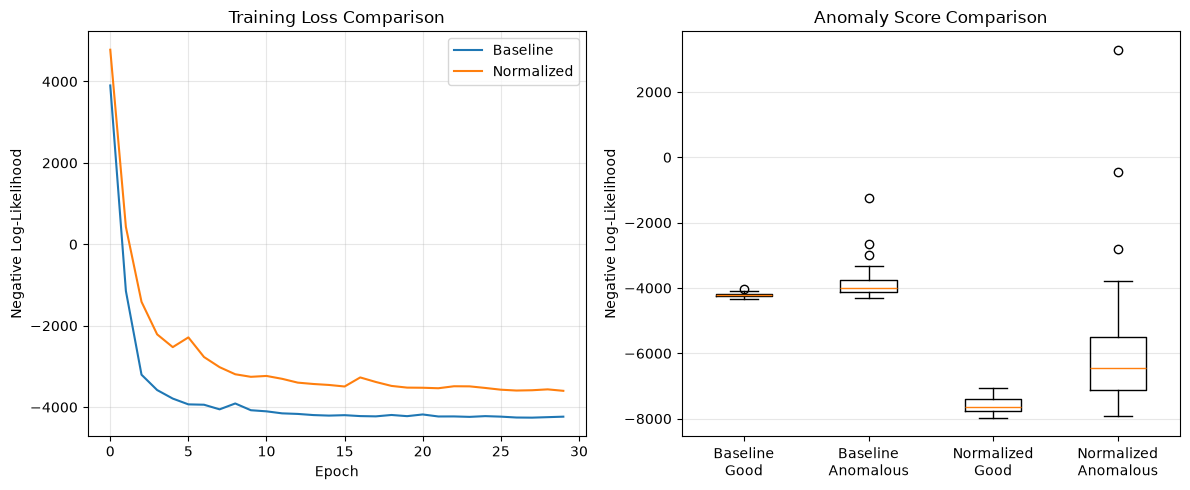

In [20]:
# ==========================================
# 5.4 EVALUATE THE NORMALIZED MODEL
# ==========================================

model_norm.eval()

normalized_test_scores = []
normalized_test_labels = []

with torch.no_grad():

    for images, labels, paths in test_loader:

        images = images.to(DEVICE)

        # Apply training-based normalization
        images_norm = (images - train_mean) / train_std

        _, log_likelihood = model_norm(images_norm)

        # Convert likelihood back to original input coordinates
        log_likelihood_original = (
            log_likelihood - INPUT_DIM * np.log(train_std)
        )

        anomaly_scores = -log_likelihood_original

        normalized_test_scores.extend(
            anomaly_scores.cpu().numpy().tolist()
        )
        normalized_test_labels.extend(labels.tolist())

normalized_test_scores = np.asarray(normalized_test_scores)
normalized_test_labels = np.asarray(normalized_test_labels)

print("Evaluated images:", len(normalized_test_scores))
print("Mean normalized-model anomaly score:",
      normalized_test_scores.mean())

# ==========================================
# 5.5 COMPARE BASELINE AND NORMALIZED MODELS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(train_losses, label="Baseline")
axes[0].plot(normalized_train_losses, label="Normalized")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Negative Log-Likelihood")
axes[0].set_title("Training Loss Comparison")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].boxplot(
    [
        test_scores[test_true_labels == 0],
        test_scores[test_true_labels == 1],
        normalized_test_scores[normalized_test_labels == 0],
        normalized_test_scores[normalized_test_labels == 1]
    ],
    tick_labels=[
        "Baseline\nGood",
        "Baseline\nAnomalous",
        "Normalized\nGood",
        "Normalized\nAnomalous"
    ]
)
axes[1].set_ylabel("Negative Log-Likelihood")
axes[1].set_title("Anomaly Score Comparison")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Input Normalization Discussion

The normalized model showed a decreasing training loss, indicating progress in optimizing its objective. However, its anomaly scores exhibited substantially greater variability than those of the baseline model, particularly for defective samples.

The score distributions alone do not establish whether input normalization improved anomaly detection. Since normalization changes the scale of the likelihood values, performance must be assessed using quantitative metrics on the same test images. The next stage will compare both models using AUROC and threshold-based classification metrics.

# 6. Anomaly Detection and Quantitative Evaluation

The baseline and normalized Normalizing Flow models are evaluated using image-level anomaly scores obtained from the negative log-likelihood. Higher scores indicate lower likelihood under the learned distribution and are treated as stronger anomaly indicators.

The evaluation compares the ability of both models to distinguish defect-free cable images from defective samples. The Area Under the Receiver Operating Characteristic Curve (AUROC) measures ranking performance independently of a fixed classification threshold, while accuracy, precision, recall, and F1-score evaluate classification at a selected threshold.

Confusion matrices are also generated to examine the number of correctly and incorrectly classified samples.

BASELINE MODEL
AUROC: 0.8817

NORMALIZED MODEL
AUROC: 0.9294


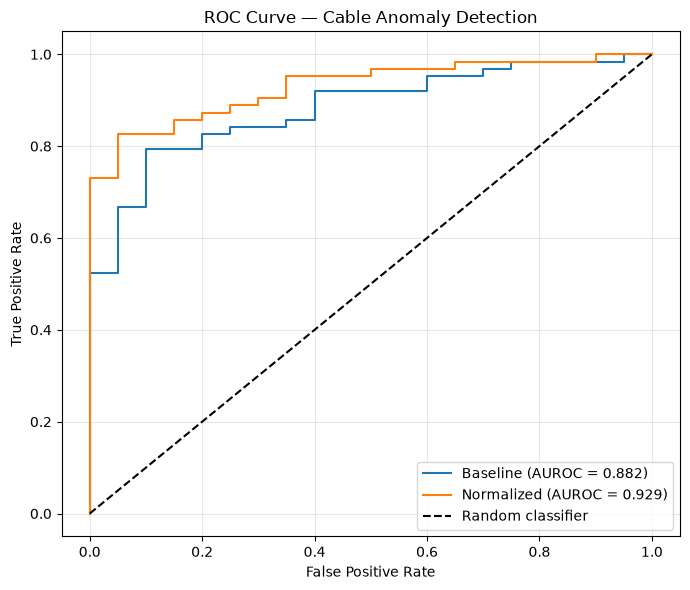

In [21]:
# ==========================================
# 6.1 CALCULATE AUROC
# ==========================================

from sklearn.metrics import roc_auc_score, roc_curve

# Calculate AUROC for both models
baseline_auroc = roc_auc_score(
    test_true_labels,
    test_scores
)

normalized_auroc = roc_auc_score(
    normalized_test_labels,
    normalized_test_scores
)

print("BASELINE MODEL")
print(f"AUROC: {baseline_auroc:.4f}")

print("\nNORMALIZED MODEL")
print(f"AUROC: {normalized_auroc:.4f}")

# Plot ROC curves
fpr_base, tpr_base, _ = roc_curve(
    test_true_labels, test_scores
)

fpr_norm, tpr_norm, _ = roc_curve(
    normalized_test_labels, normalized_test_scores
)

plt.figure(figsize=(7, 6))
plt.plot(
    fpr_base, tpr_base,
    label=f"Baseline (AUROC = {baseline_auroc:.3f})"
)
plt.plot(
    fpr_norm, tpr_norm,
    label=f"Normalized (AUROC = {normalized_auroc:.3f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Cable Anomaly Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Baseline threshold: -4137.7232421875
Normalized threshold: -7420.17060546875

BASELINE MODEL
----------------------------------------
Accuracy:  0.8072
Precision: 0.9608
Recall:    0.7778
F1-score:  0.8596

Classification report:
              precision    recall  f1-score   support

        Good       0.56      0.90      0.69        20
   Anomalous       0.96      0.78      0.86        63

    accuracy                           0.81        83
   macro avg       0.76      0.84      0.78        83
weighted avg       0.86      0.81      0.82        83


NORMALIZED MODEL
----------------------------------------
Accuracy:  0.8434
Precision: 0.9032
Recall:    0.8889
F1-score:  0.8960

Classification report:
              precision    recall  f1-score   support

        Good       0.67      0.70      0.68        20
   Anomalous       0.90      0.89      0.90        63

    accuracy                           0.84        83
   macro avg       0.78      0.79      0.79        83
weighted avg    

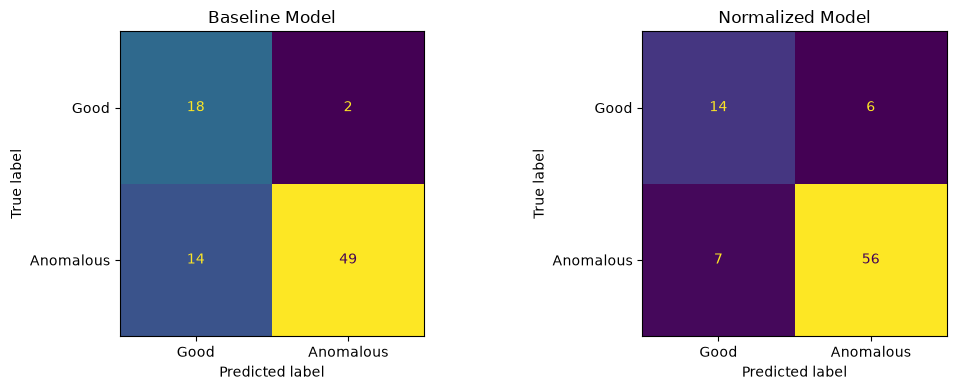

In [22]:
# ==========================================
# 6.2 SELECT CLASSIFICATION THRESHOLDS
# ==========================================

# Calculate anomaly scores for normal training images
def calculate_training_scores(model_to_evaluate, normalize=False):

    model_to_evaluate.eval()
    scores = []

    with torch.no_grad():
        for images in train_loader:

            images = images.to(DEVICE)

            if normalize:
                images = (images - train_mean) / train_std

            _, log_likelihood = model_to_evaluate(images)

            # Correct the density for input normalization
            if normalize:
                log_likelihood = (
                    log_likelihood - INPUT_DIM * np.log(train_std)
                )

            scores.extend((-log_likelihood).cpu().numpy().tolist())

    return np.asarray(scores)


baseline_train_scores = calculate_training_scores(
    model,
    normalize=False
)

normalized_train_scores = calculate_training_scores(
    model_norm,
    normalize=True
)

# Set thresholds using only normal training data
baseline_threshold = np.percentile(baseline_train_scores, 90)
normalized_threshold = np.percentile(normalized_train_scores, 90)

print("Baseline threshold:", baseline_threshold)
print("Normalized threshold:", normalized_threshold)

# ==========================================
# 6.3 CONFUSION MATRICES AND METRICS
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Predict normal (0) or anomalous (1)
baseline_predictions = (
    test_scores > baseline_threshold
).astype(int)

normalized_predictions = (
    normalized_test_scores > normalized_threshold
).astype(int)


def evaluate_predictions(y_true, y_pred, model_name):

    print(f"\n{model_name}")
    print("-" * 40)

    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_true, y_pred, zero_division=0):.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Good", "Anomalous"],
        zero_division=0
    ))

    return confusion_matrix(y_true, y_pred)


baseline_cm = evaluate_predictions(
    test_true_labels,
    baseline_predictions,
    "BASELINE MODEL"
)

normalized_cm = evaluate_predictions(
    normalized_test_labels,
    normalized_predictions,
    "NORMALIZED MODEL"
)

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix=baseline_cm,
    display_labels=["Good", "Anomalous"]
).plot(ax=axes[0], colorbar=False, values_format="d")

axes[0].set_title("Baseline Model")

ConfusionMatrixDisplay(
    confusion_matrix=normalized_cm,
    display_labels=["Good", "Anomalous"]
).plot(ax=axes[1], colorbar=False, values_format="d")

axes[1].set_title("Normalized Model")

plt.tight_layout()
plt.show()


In [23]:
# ==========================================
# 6.4 COMPARE MODEL PERFORMANCE
# ==========================================

comparison = {
    "Metric": ["AUROC", "Accuracy", "Precision", "Recall", "F1-score"],
    "Baseline": [
        baseline_auroc,
        accuracy_score(test_true_labels, baseline_predictions),
        precision_score(test_true_labels, baseline_predictions, zero_division=0),
        recall_score(test_true_labels, baseline_predictions, zero_division=0),
        f1_score(test_true_labels, baseline_predictions, zero_division=0)
    ],
    "Normalized": [
        normalized_auroc,
        accuracy_score(normalized_test_labels, normalized_predictions),
        precision_score(normalized_test_labels, normalized_predictions, zero_division=0),
        recall_score(normalized_test_labels, normalized_predictions, zero_division=0),
        f1_score(normalized_test_labels, normalized_predictions, zero_division=0)
    ]
}

for i, metric in enumerate(comparison["Metric"]):
    print(
        f"{metric:12s} | "
        f"Baseline: {comparison['Baseline'][i]:.4f} | "
        f"Normalized: {comparison['Normalized'][i]:.4f}"
    )



AUROC        | Baseline: 0.8817 | Normalized: 0.9294
Accuracy     | Baseline: 0.8072 | Normalized: 0.8434
Precision    | Baseline: 0.9608 | Normalized: 0.9032
Recall       | Baseline: 0.7778 | Normalized: 0.8889
F1-score     | Baseline: 0.8596 | Normalized: 0.8960
